<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session10_recurrent_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۰: شبکه‌های عصبی بازگشتی (RNN) و داده دنباله‌ای

### اهداف این جلسه

- شناخت ویژگی‌های داده دنباله‌ای و انواع مسائل دنباله‌ای
- پیاده‌سازی سلول RNN از صفر و تطبیق آن با `nn.RNN`
- تسلط بر ابعاد ورودی و خروجی RNN در PyTorch
- درک Backpropagation Through Time، انفجار و محوشدگی گرادیان و Gradient Clipping
- پیش‌بینی سری زمانی با RNN و مشاهده محدودیت RNN در وابستگی‌های بلندمدت

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. داده دنباله‌ای (Sequential Data)

تا اینجا ورودی مدل‌های ما اندازه ثابتی داشت و ترتیب نمونه‌ها مهم نبود. اما بسیاری از داده‌های مهم **دنباله‌ای** هستند و ترتیب در آن‌ها معنا دارد:

- **متن:** «سگ گربه را دنبال کرد» با «گربه سگ را دنبال کرد» فرق دارد.
- **سری زمانی (Time Series):** قیمت، دما، مصرف برق، داده حسگرها.
- **صوت و گفتار، ویدیو، توالی DNA و رویدادهای کاربر.**

چالش‌ها: طول دنباله‌ها **متغیر** است و اطلاعات مهم ممکن است در فاصله دوری از هم باشند. MLP ورودی با طول ثابت می‌خواهد و برای هر مکان وزن جدا دارد.

**شبکه عصبی بازگشتی (Recurrent Neural Network, RNN)** دنباله را **گام‌به‌گام** پردازش می‌کند و یک **حالت پنهان (Hidden State)** $\mathbf{h}_t$ را به‌عنوان «حافظه» از هر گام به گام بعد منتقل می‌کند. مشابه اشتراک وزن در CNN که در **مکان** بود، RNN وزن‌ها را در **زمان** به اشتراک می‌گذارد.

### انواع مسائل دنباله‌ای

| نوع | ورودی ← خروجی | مثال |
|---|---|---|
| Many-to-One | دنباله ← یک برچسب | تحلیل احساس جمله، طبقه‌بندی سری زمانی |
| One-to-Many | یک ورودی ← دنباله | تولید توضیح برای تصویر (Image Captioning) |
| Many-to-Many (هم‌طول) | دنباله ← دنباله هم‌طول | برچسب‌گذاری اجزای کلام (POS Tagging)، تشخیص موجودیت‌های نام‌دار (NER) |
| Sequence-to-Sequence | دنباله ← دنباله با طول متفاوت | ترجمه ماشینی، خلاصه‌سازی (جلسه ۱۲) |

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)
np.random.seed(42)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. سلول RNN

در هر گام زمانی $t$، سلول RNN ورودی فعلی $\mathbf{x}_t$ و حالت پنهان قبلی $\mathbf{h}_{t-1}$ را ترکیب می‌کند:

$$\mathbf{h}_t = \tanh\left(W_{xh}\,\mathbf{x}_t + W_{hh}\,\mathbf{h}_{t-1} + \mathbf{b}_h\right)$$

و در صورت نیاز یک خروجی از روی حالت پنهان می‌سازد: $\hat{\mathbf{y}}_t = W_{hy}\,\mathbf{h}_t + \mathbf{b}_y$. **همان** ماتریس‌های $W_{xh}$ و $W_{hh}$ در همه گام‌های زمانی استفاده می‌شوند؛ پس تعداد پارامترها به طول دنباله بستگی ندارد. $\mathbf{h}_0$ معمولاً صفر است.

اگر حلقه زمانی را **باز کنیم (Unroll)**، RNN شبیه یک شبکه عمیق است که عمقش برابر طول دنباله است و همه لایه‌هایش وزن مشترک دارند. پیاده‌سازی از صفر:

</div>

In [2]:
class MyRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_xh = nn.Linear(input_size, hidden_size)            # includes b_h
        self.W_hh = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x, h0=None):
        """x: (batch, seq_len, input_size) -> outputs: (batch, seq_len, hidden), h_T: (batch, hidden)"""
        batch, seq_len, _ = x.shape
        h = torch.zeros(batch, self.hidden_size, device=x.device) if h0 is None else h0
        outputs = []
        for t in range(seq_len):                                  # the recurrence
            h = torch.tanh(self.W_xh(x[:, t]) + self.W_hh(h))
            outputs.append(h)
        return torch.stack(outputs, dim=1), h


my_rnn = MyRNN(input_size=3, hidden_size=5)
x = torch.randn(2, 7, 3)                                          # batch of 2 sequences, 7 steps, 3 features
out, h_last = my_rnn(x)
print('outputs:', tuple(out.shape), '| last hidden state:', tuple(h_last.shape))
print('number of parameters:', sum(p.numel() for p in my_rnn.parameters()), '(independent of sequence length)')

outputs: (2, 7, 5) | last hidden state: (2, 5)
number of parameters: 45 (independent of sequence length)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### `nn.RNN` در PyTorch

`nn.RNN` همین محاسبه را به‌صورت بهینه (با پیاده‌سازی cuDNN روی GPU) انجام می‌دهد. دو نکته مهم درباره ابعاد:

- با `batch_first=True` ورودی شکل `(batch, seq_len, input_size)` دارد (پیش‌فرض PyTorch `(seq_len, batch, input_size)` است).
- خروجی یک زوج است: `output` با شکل `(batch, seq_len, hidden_size)` شامل حالت پنهان **همه** گام‌ها، و `h_n` با شکل `(num_layers, batch, hidden_size)` شامل حالت پنهان **آخرین** گام برای هر لایه.

برای اطمینان از درک درست، وزن‌های `nn.RNN` را در پیاده‌سازی خودمان کپی می‌کنیم و خروجی‌ها را مقایسه می‌کنیم:

</div>

In [3]:
rnn = nn.RNN(input_size=3, hidden_size=5, batch_first=True)
with torch.no_grad():
    my_rnn.W_xh.weight.copy_(rnn.weight_ih_l0)
    my_rnn.W_xh.bias.copy_(rnn.bias_ih_l0 + rnn.bias_hh_l0)       # PyTorch keeps two bias vectors
    my_rnn.W_hh.weight.copy_(rnn.weight_hh_l0)

out_ref, h_n = rnn(x)
out_mine, h_mine = my_rnn(x)
print('output shape:', tuple(out_ref.shape), '| h_n shape:', tuple(h_n.shape))
print('outputs match:', torch.allclose(out_ref, out_mine, atol=1e-6))
print('h_n equals the last output step:', torch.allclose(h_n[0], out_ref[:, -1]))

output shape: (2, 7, 5) | h_n shape: (1, 2, 5)
outputs match: True
h_n equals the last output step: True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**RNN چندلایه (Stacked)** با `num_layers=2` یا بیشتر ساخته می‌شود: دنباله خروجی لایه اول، ورودی لایه دوم است. **RNN دوطرفه (Bidirectional)** با `bidirectional=True` دنباله را یک بار از ابتدا به انتها و یک بار برعکس پردازش می‌کند و خروجی‌ها را کنار هم می‌گذارد؛ برای مسائلی مثل طبقه‌بندی متن که کل دنباله از ابتدا در دسترس است مفید است.

</div>

In [4]:
deep_bi = nn.RNN(input_size=3, hidden_size=5, num_layers=2, bidirectional=True, batch_first=True)
out, h_n = deep_bi(x)
print('output:', tuple(out.shape), '-> last dim = 2 directions x hidden_size')
print('h_n   :', tuple(h_n.shape), '-> num_layers x num_directions')

output: (2, 7, 10) -> last dim = 2 directions x hidden_size
h_n   : (4, 2, 5) -> num_layers x num_directions


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. Backpropagation Through Time و مشکل گرادیان

آموزش RNN همان Backpropagation روی گراف بازشده در زمان است که به آن **Backpropagation Through Time (BPTT)** می‌گویند. گرادیان Loss نسبت به حالت پنهان اولیه شامل حاصل‌ضرب ژاکوبین‌های همه گام‌هاست:

$$\frac{\partial \mathbf{h}_T}{\partial \mathbf{h}_0} = \prod_{t=1}^{T} \frac{\partial \mathbf{h}_t}{\partial \mathbf{h}_{t-1}} = \prod_{t=1}^{T} \text{diag}\left(1 - \mathbf{h}_t^2\right) W_{hh}$$

حاصل‌ضرب $T$ ماتریس، بسته به بزرگی $W_{hh}$ (دقیق‌تر: بزرگ‌ترین مقدار تکین آن)، به‌صورت نمایی یا **منفجر** می‌شود یا **محو**. آزمایش:

</div>

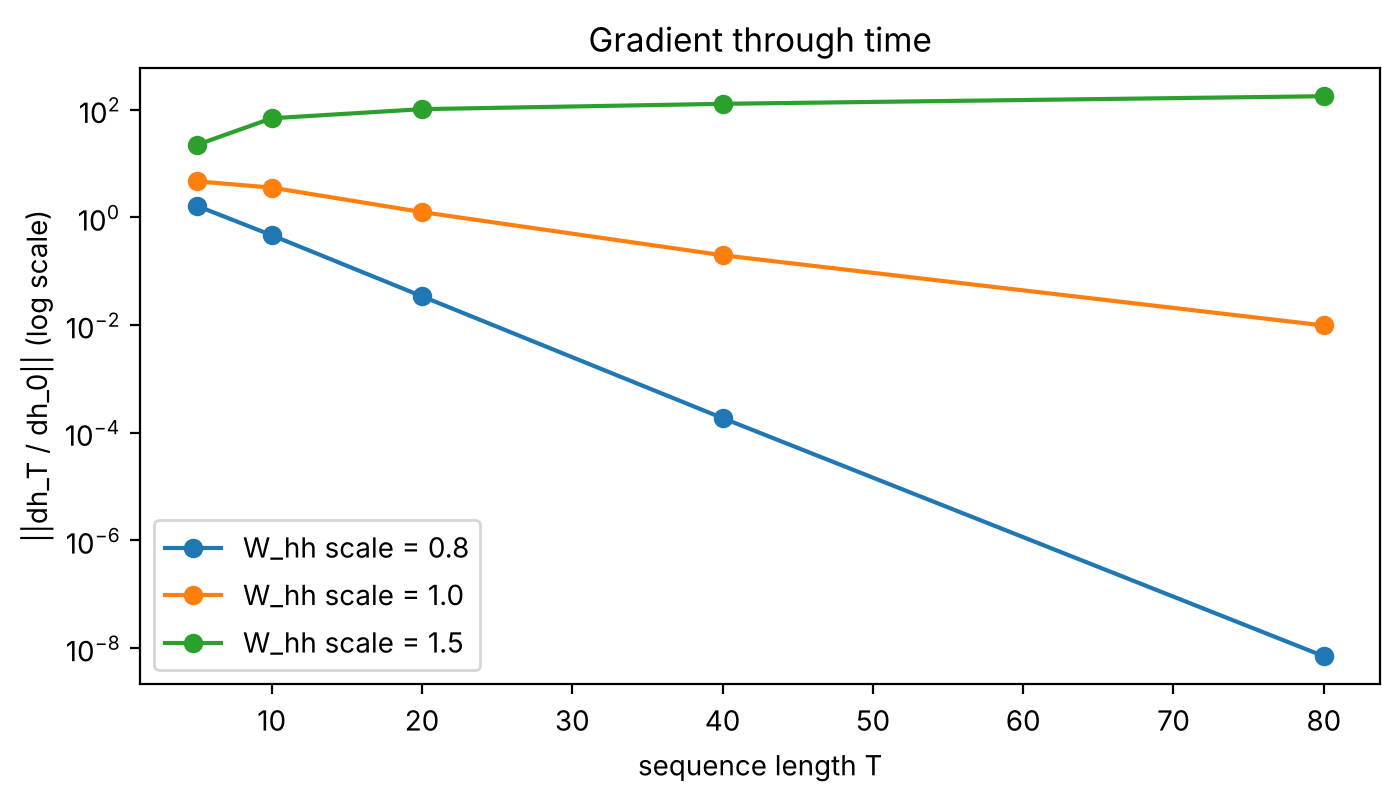

In [5]:
def grad_wrt_h0(seq_len, scale, hidden=32, seed=0):
    torch.manual_seed(seed)
    cell = nn.RNN(1, hidden, batch_first=True, nonlinearity='tanh')
    with torch.no_grad():
        q, _ = torch.linalg.qr(torch.randn(hidden, hidden))
        cell.weight_hh_l0.copy_(scale * q)                        # orthogonal matrix times `scale`
        cell.weight_ih_l0.mul_(0.1)
    h0 = torch.zeros(1, 1, hidden, requires_grad=True)
    out, _ = cell(torch.randn(1, seq_len, 1) * 0.1, h0)
    out[:, -1].sum().backward()
    return h0.grad.norm().item()


lengths = [5, 10, 20, 40, 80]
plt.figure(figsize=(8, 4))
for scale in (0.8, 1.0, 1.5):
    plt.semilogy(lengths, [grad_wrt_h0(T, scale) for T in lengths], 'o-', label=f'W_hh scale = {scale}')
plt.xlabel('sequence length T'); plt.ylabel('||dh_T / dh_0|| (log scale)'); plt.legend()
plt.title('Gradient through time'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- با مقیاس کوچک‌تر از ۱، گرادیان به‌صورت نمایی **محو** می‌شود: RNN نمی‌تواند وابستگی‌های بلندمدت را یاد بگیرد. حتی با مقیاس ۱، چون مشتق Tanh کوچک‌تر از ۱ است، گرادیان آرام‌آرام محو می‌شود.
- با مقیاس بزرگ، گرادیان در ابتدا رشد می‌کند (و با وزن‌های بزرگ‌تر یا تابع فعال‌سازی بدون اشباع، **منفجر** می‌شود). در اینجا اشباع تابع Tanh مانع انفجار کامل شده است.

### Gradient Clipping

راه‌حل ساده و استاندارد برای **انفجار** گرادیان: اگر نُرم کل گرادیان از آستانه‌ای بیشتر شد، آن را مقیاس می‌کنیم تا نُرمش برابر آستانه شود. جهت گرادیان حفظ می‌شود و فقط طول قدم محدود می‌شود. در PyTorch بین `backward()` و `step()`:

```python
loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()
```

برای **محوشدگی** گرادیان به راه‌حل معماری نیاز داریم: LSTM و GRU (جلسه ۱۱).

## ۴. پیش‌بینی سری زمانی

یک سری زمانی مصنوعی می‌سازیم: مجموع دو موج سینوسی با دوره‌های متفاوت به‌علاوه نویز. وظیفه مدل: با دیدن ۵۰ مقدار اخیر، مقدار بعدی را پیش‌بینی کند (**Many-to-One**).

</div>

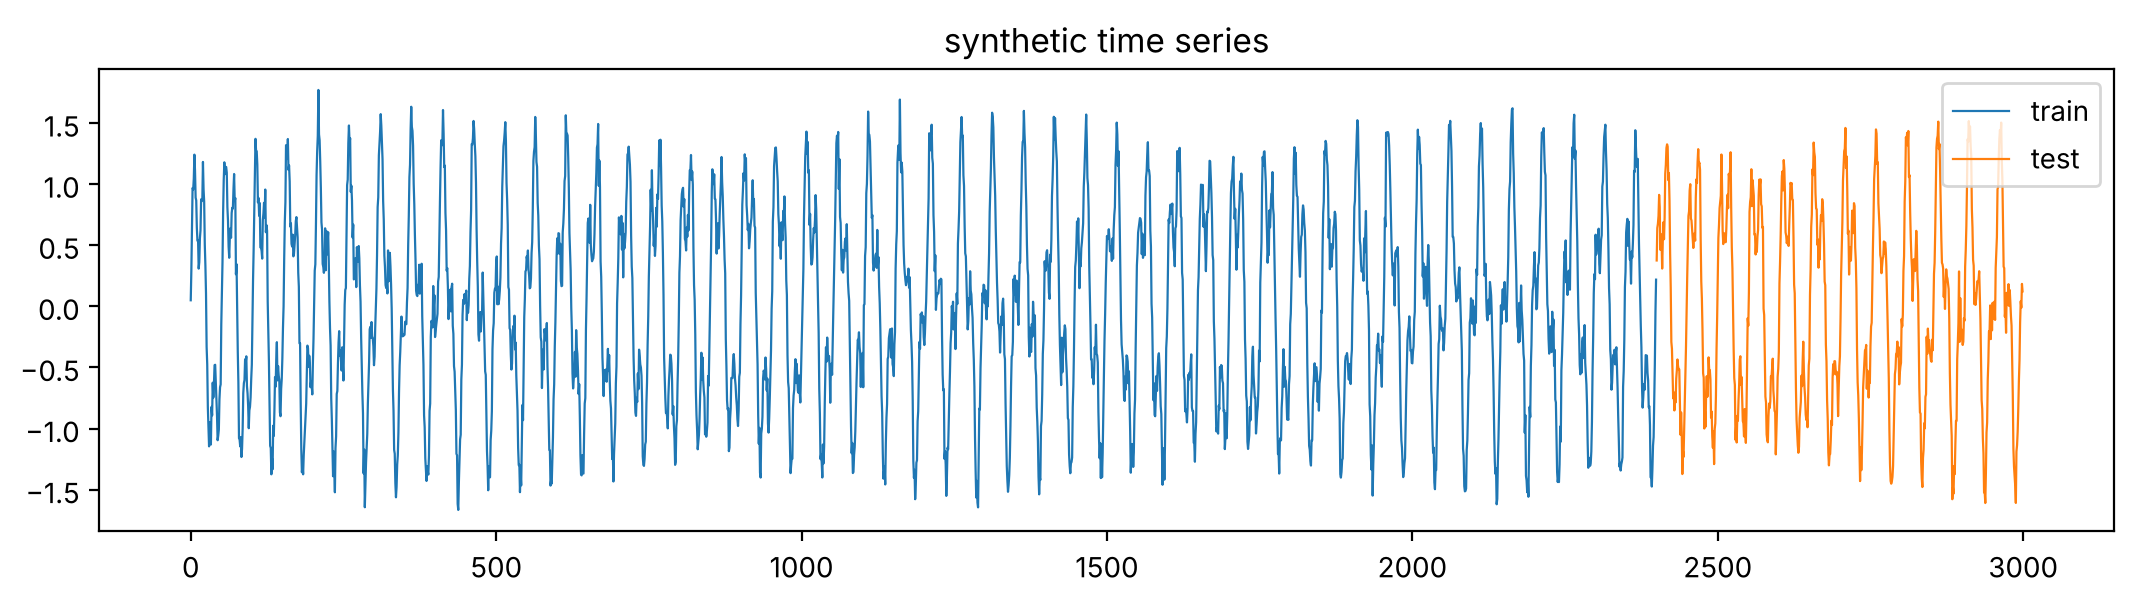

In [6]:
t = np.arange(0, 3000)
series = np.sin(2 * np.pi * t / 50) + 0.5 * np.sin(2 * np.pi * t / 17) + 0.1 * np.random.randn(len(t))
series = series.astype(np.float32)

split = 2400                                    # chronological split: never shuffle time before splitting
train_series, test_series = series[:split], series[split:]
mean, std = train_series.mean(), train_series.std()
norm = lambda s: (s - mean) / std               # statistics from the training part only

plt.figure(figsize=(13, 3))
plt.plot(t[:split], series[:split], lw=0.8, label='train')
plt.plot(t[split:], series[split:], lw=0.8, label='test')
plt.legend(); plt.title('synthetic time series'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**نکته مهم:** در سری زمانی داده را **بر اساس زمان** تقسیم می‌کنیم، نه تصادفی؛ وگرنه مدل از آینده برای پیش‌بینی گذشته استفاده می‌کند و ارزیابی غیرواقعی می‌شود.

با یک **پنجره لغزان (Sliding Window)** نمونه‌ها را می‌سازیم:

</div>

In [7]:
class WindowDataset(Dataset):
    def __init__(self, series, window=50):
        self.x = torch.tensor(series)
        self.window = window

    def __len__(self):
        return len(self.x) - self.window

    def __getitem__(self, i):
        seq = self.x[i:i + self.window].unsqueeze(-1)            # (window, 1): one feature per step
        target = self.x[i + self.window].unsqueeze(-1)            # the next value
        return seq, target


WINDOW = 50
train_ds = WindowDataset(norm(train_series), WINDOW)
test_ds = WindowDataset(norm(test_series), WINDOW)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256)
xb, yb = next(iter(train_loader))
print('input batch:', tuple(xb.shape), '| target batch:', tuple(yb.shape))

input batch: (64, 50, 1) | target batch: (64, 1)


In [8]:
class RNNForecaster(nn.Module):
    def __init__(self, hidden_size=64, num_layers=1, cell=nn.RNN):
        super().__init__()
        self.rnn = cell(input_size=1, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])                              # many-to-one: use the last time step


def train_regressor(model, epochs=15, lr=1e-3, clip=1.0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for epoch in range(1, epochs + 1):
        model.train()
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            loss = loss_fn(model(X), y)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)   # gradient clipping
            opt.step()
        if epoch % 5 == 0:
            print(f'epoch {epoch:2d} | test MSE {test_mse(model):.4f}')
    return model


@torch.no_grad()
def test_mse(model):
    model.eval()
    errs = [((model(X.to(device)) - y.to(device)) ** 2).sum().item() for X, y in test_loader]
    return sum(errs) / len(test_ds)


torch.manual_seed(0)
rnn_model = train_regressor(RNNForecaster())

naive = np.mean((norm(test_series)[WINDOW:] - norm(test_series)[WINDOW - 1:-1]) ** 2)
print(f'\nnaive baseline (tomorrow = today) MSE: {naive:.4f}')
print(f'noise floor (noise variance / series variance): {0.1 ** 2 / std ** 2:.4f}')

epoch  5 | test MSE 0.0340


epoch 10 | test MSE 0.0223


epoch 15 | test MSE 0.0228

naive baseline (tomorrow = today) MSE: 0.0694
noise floor (noise variance / series variance): 0.0156


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

همیشه مدل را با یک **خط مبنای ساده (Naive Baseline)** مقایسه کنید؛ در سری زمانی رایج‌ترینش «مقدار بعدی برابر مقدار فعلی» است. RNN خطا را تا نزدیکی سطح نویز پایین می‌آورد؛ کمتر از آن ممکن نیست چون نویز تصادفی قابل پیش‌بینی نیست.

### پیش‌بینی چندگامی (Autoregressive)

برای پیش‌بینی چند گام جلوتر، هر پیش‌بینی را به انتهای پنجره اضافه می‌کنیم و دوباره پیش‌بینی می‌کنیم. خطا در این روش انباشته می‌شود:

</div>

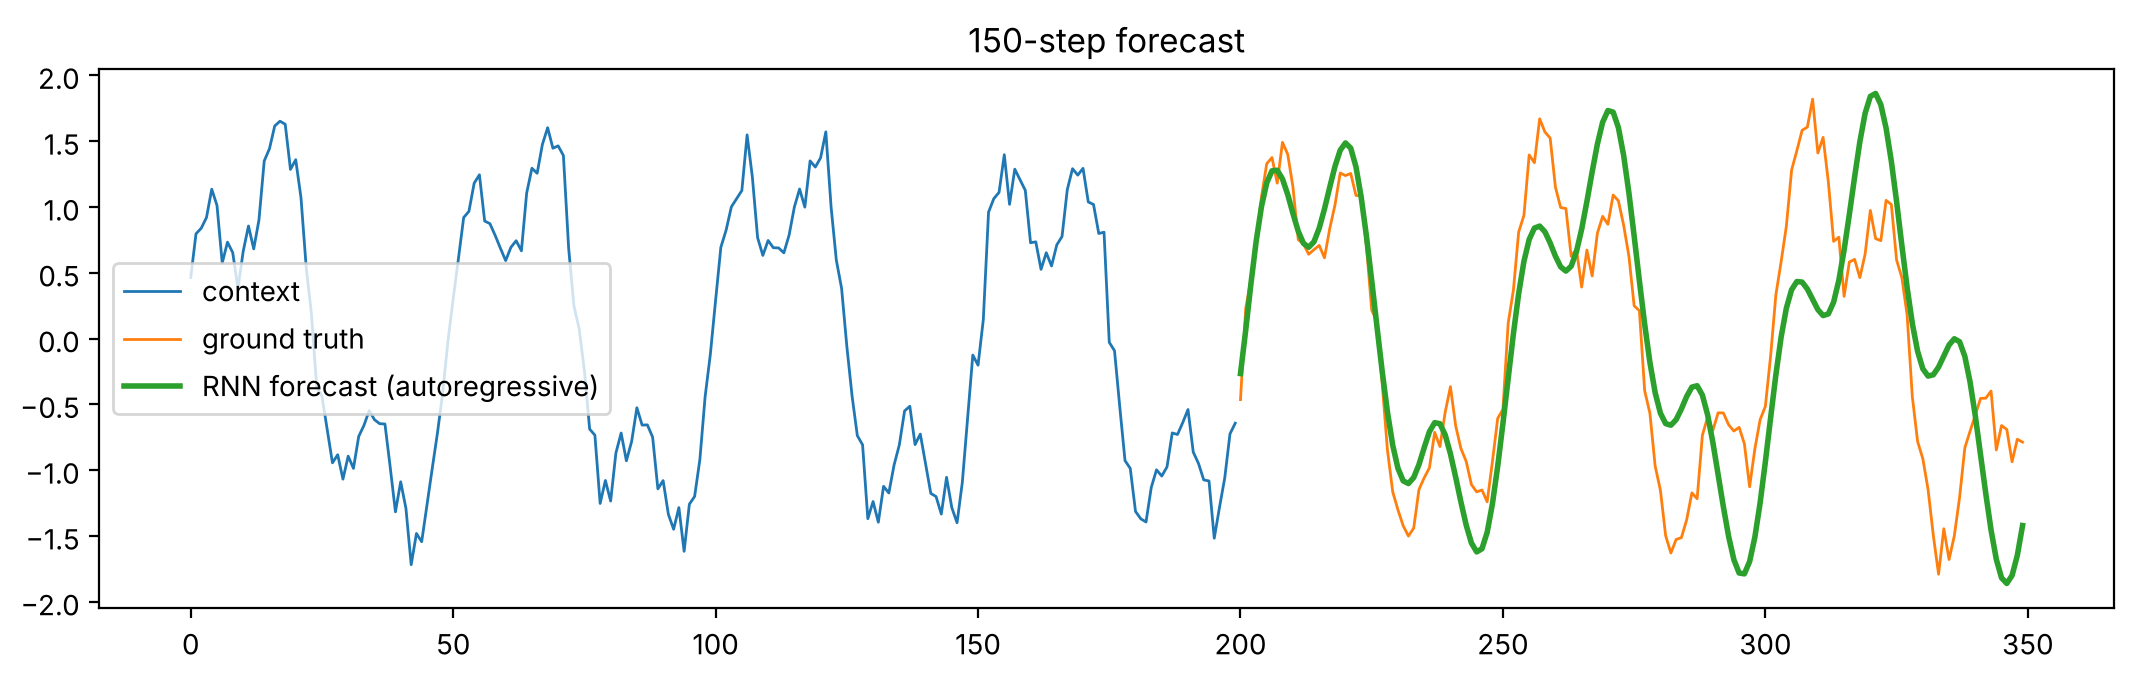

In [9]:
@torch.no_grad()
def forecast(model, history, steps):
    model.eval()
    window = torch.tensor(history[-WINDOW:]).view(1, WINDOW, 1).to(device)
    preds = []
    for _ in range(steps):
        nxt = model(window)                                       # (1, 1)
        preds.append(nxt.item())
        window = torch.cat([window[:, 1:], nxt.view(1, 1, 1)], dim=1)
    return np.array(preds)


test_norm = norm(test_series)
context, horizon = test_norm[:200], 150
pred = forecast(rnn_model, context, horizon)
plt.figure(figsize=(13, 3.5))
plt.plot(range(200), context, label='context', lw=1)
plt.plot(range(200, 200 + horizon), test_norm[200:200 + horizon], label='ground truth', lw=1)
plt.plot(range(200, 200 + horizon), pred, label='RNN forecast (autoregressive)', lw=2)
plt.legend(); plt.title('150-step forecast'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. محدودیت RNN: وابستگی‌های بلندمدت

یک مسئله ساده اما سخت برای RNN طراحی می‌کنیم: دنباله‌ای از اعداد تصادفی می‌گیریم و برچسب، **علامت اولین عدد** است. بقیه دنباله فقط نویز است. مدل باید اطلاعات گام اول را تا پایان دنباله در حافظه نگه دارد. RNN ساده را با LSTM (موضوع جلسه بعد) با تعداد گام‌های مختلف مقایسه می‌کنیم:

</div>

RNN   T=5: 1.00 T=20: 0.49 T=50: 0.50 T=100: 0.50
LSTM  T=5: 1.00 T=20: 1.00 T=50: 0.99 T=100: 0.99


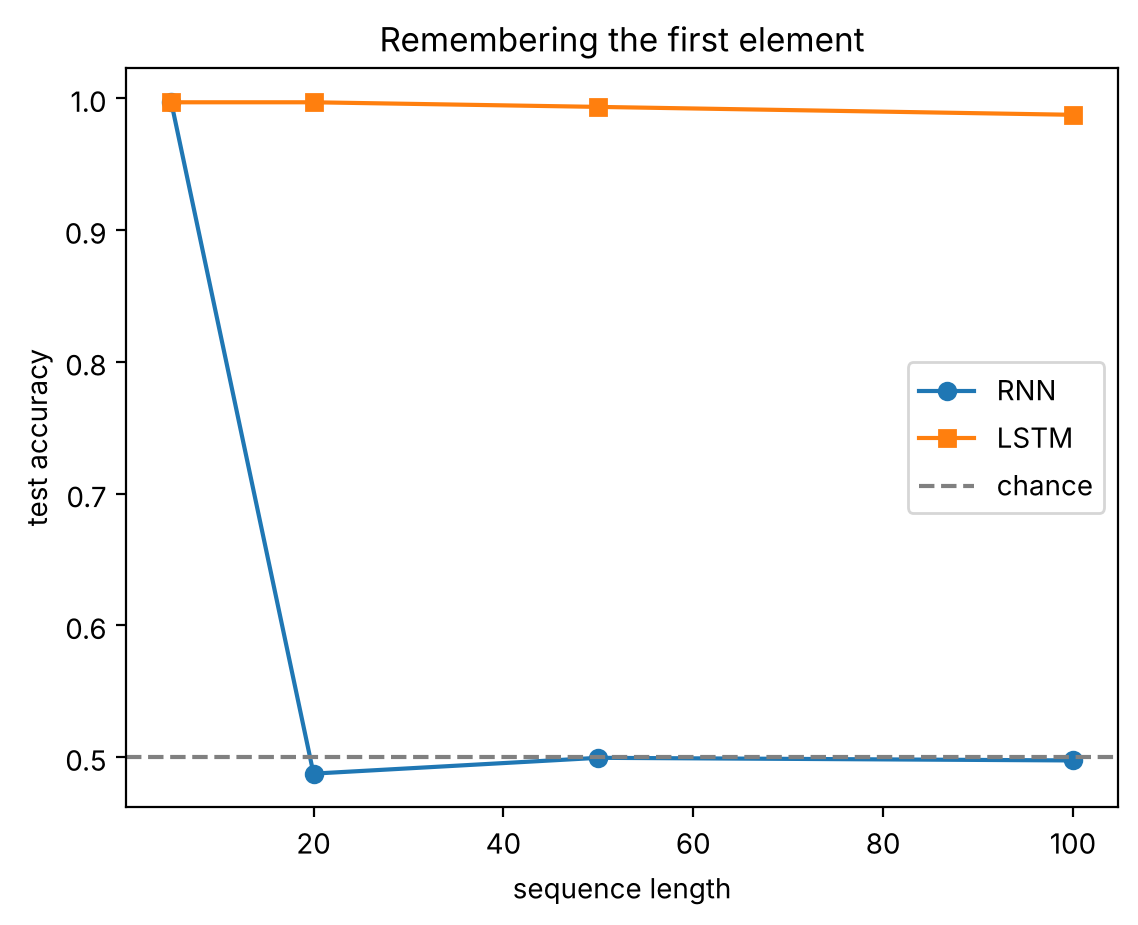

In [10]:
def make_memory_task(n, seq_len):
    x = torch.randn(n, seq_len, 1)
    y = (x[:, 0, 0] > 0).long()                                    # label = sign of the FIRST element
    return x, y


class SeqClassifier(nn.Module):
    def __init__(self, cell, hidden=32):
        super().__init__()
        self.rnn = cell(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 2)
        if cell is nn.LSTM:                                        # large forget-gate bias: remember by default
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden:2 * hidden].fill_(4.0)
                self.rnn.bias_hh_l0[hidden:2 * hidden].zero_()

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])


def memory_accuracy(cell, seq_len, steps=1500):
    torch.manual_seed(0)
    model = SeqClassifier(cell).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x, y = make_memory_task(64, seq_len)
        loss = nn.functional.cross_entropy(model(x.to(device)), y.to(device))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    x, y = make_memory_task(2000, seq_len)
    with torch.no_grad():
        return (model(x.to(device)).argmax(1).cpu() == y).float().mean().item()


lengths = [5, 20, 50, 100]
acc = {name: [memory_accuracy(cell, T) for T in lengths] for name, cell in [('RNN', nn.RNN), ('LSTM', nn.LSTM)]}
for name, a in acc.items():
    print(f'{name:5s}', ' '.join(f'T={T}: {v:.2f}' for T, v in zip(lengths, a)))

plt.plot(lengths, acc['RNN'], 'o-', label='RNN'); plt.plot(lengths, acc['LSTM'], 's-', label='LSTM')
plt.axhline(0.5, ls='--', color='gray', label='chance')
plt.xlabel('sequence length'); plt.ylabel('test accuracy'); plt.legend(); plt.title('Remembering the first element')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

(در LSTM، بایاس «دروازه فراموشی» را عددی مثبت مقداردهی کردیم تا شبکه به‌طور پیش‌فرض اطلاعات را نگه دارد؛ یک ترفند رایج (Jozefowicz et al., 2015) که معنایش را جلسه بعد می‌فهمیم.)

RNN ساده برای دنباله‌های کوتاه موفق است، اما با افزایش فاصله بین اطلاعات مهم و لحظه تصمیم‌گیری، دقتش به سطح شانس (۵۰٪) سقوط می‌کند: این همان اثر محوشدگی گرادیان است. LSTM با یک تغییر معماری ساده این مشکل را تا حد زیادی حل می‌کند. چطور؟ جلسه بعد!

## جمع‌بندی

- داده دنباله‌ای ترتیب‌دار و با طول متغیر است؛ RNN آن را گام‌به‌گام با یک حالت پنهان پردازش می‌کند.
- $\mathbf{h}_t = \tanh(W_{xh}\mathbf{x}_t + W_{hh}\mathbf{h}_{t-1} + \mathbf{b})$؛ وزن‌ها در زمان مشترک‌اند.
- در PyTorch با `batch_first=True`: ورودی `(batch, seq, features)`؛ خروجی `output` (همه گام‌ها) و `h_n` (گام آخر).
- آموزش با BPTT؛ حاصل‌ضرب ژاکوبین‌ها باعث انفجار یا محوشدگی گرادیان می‌شود.
- انفجار: Gradient Clipping با `clip_grad_norm_`. محوشدگی: LSTM و GRU.
- در سری زمانی: تقسیم زمانی داده، نرمال‌سازی با آمار آموزش، و مقایسه با خط مبنای ساده.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. `MyRNN` را طوری تغییر دهید که `num_layers` را پشتیبانی کند و خروجی را با `nn.RNN(num_layers=2)` مقایسه کنید.

۲. در مسئله سری زمانی، طول پنجره را ۱۰، ۲۵ و ۱۰۰ بگیرید. کدام بهتر است؟ چرا پنجره ۱۰ کافی نیست؟ (راهنمایی: دوره موج‌ها.)

۳. در `train_regressor`، Gradient Clipping را حذف و نرخ یادگیری را ۰٫۰۵ کنید. نمودار Loss در هر Batch را رسم کنید.

۴. `RNNForecaster` را با `cell=nn.GRU` و `cell=nn.LSTM` آموزش دهید و خطای آزمون را مقایسه کنید.

۵. یک سری زمانی واقعی (مثلاً داده روزانه مصرف برق یا دمای یک شهر از Kaggle) را با همین کد پیش‌بینی کنید و با خط مبنای ساده مقایسه کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** `MyRNN` را طوری تغییر دهید که `num_layers` را پشتیبانی کند و خروجی را با `nn.RNN(num_layers=2)` مقایسه کنید.

</div>

In [11]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** در مسئله سری زمانی، طول پنجره را ۱۰، ۲۵ و ۱۰۰ بگیرید. کدام بهتر است؟ چرا پنجره ۱۰ کافی نیست؟ (راهنمایی: دوره موج‌ها.)

</div>

In [12]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در `train_regressor`، Gradient Clipping را حذف و نرخ یادگیری را ۰٫۰۵ کنید. نمودار Loss در هر Batch را رسم کنید.

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** `RNNForecaster` را با `cell=nn.GRU` و `cell=nn.LSTM` آموزش دهید و خطای آزمون را مقایسه کنید.

</div>

In [14]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** یک سری زمانی واقعی (مثلاً داده روزانه مصرف برق یا دمای یک شهر از Kaggle) را با همین کد پیش‌بینی کنید و با خط مبنای ساده مقایسه کنید.

</div>

In [15]:
# پاسخ خود را اینجا بنویسید
